# 1. 模型：五次恢复力把井挖浅、把山顶削平

**【原文】** Eq.(2)：

$$\ddot x+k\dot x-x^3+x^5=\lambda\cos(\omega t),\qquad
V(x)=-\frac{x^4}{4}+\frac{x^6}{6},\qquad F(x)=x^3-x^5$$

**【推断】** 符号不能写错。若写成 $-x^3-x^5$，势函数是 $-x^4/4-x^6/6$，单调无界、一个阱都没有，
"阱间跳跃"这个物理基础当场消失。五次项必须是**加号**。

**【推断】** 与经典 Holmes–Duffing 相比，两点变化：阱深 $0.25\to1/12$（÷3）；
原点附近 $V\propto-x^4$，一、二、三阶导数全为零，山顶被削成平台。
准静态倾覆门槛 $\max|V'|$ 从 $2/(3\sqrt3)=0.385$ 降到 $0.186$（$-6.3$ dB）。


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


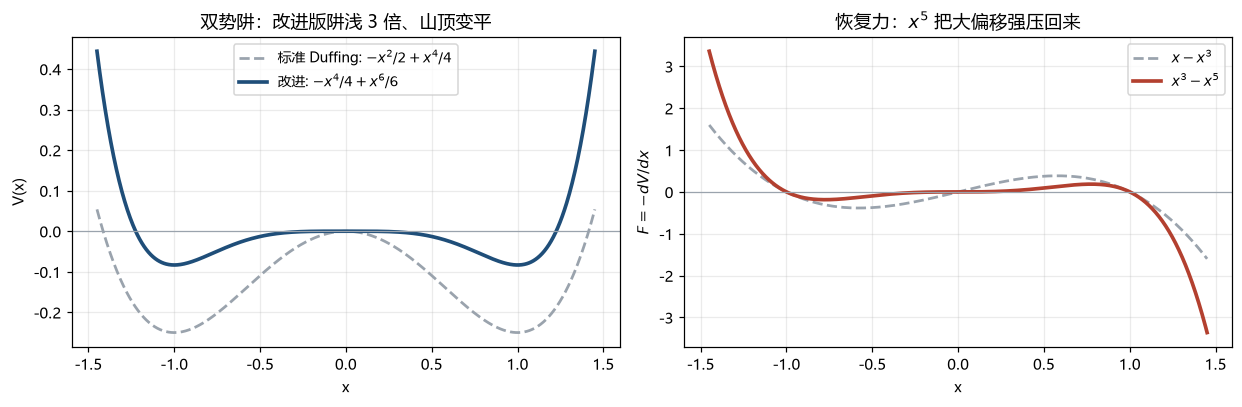

图已保存: ..\复现输出\s2-figs\s2-01-势函数与恢复力.png
阱深：经典 0.2500   五次 0.0833   比值 3.00
准静态倾覆 max|V'|：经典 0.3849   五次 0.1789
  -> -6.7 dB


In [2]:

x = np.linspace(-1.45, 1.45, 900)
V5 = -x**4/4 + x**6/6
V3 = -x**2/2 + x**4/4
F5 = x**3 - x**5
F3 = x - x**3

fig, ax = plt.subplots(1, 2, figsize=(11.4, 3.8))
ax[0].plot(x, V3, "--", color="#9aa3ad", lw=1.8, label=r"标准 Duffing: $-x^2/2+x^4/4$")
ax[0].plot(x, V5, color="#1f4e79", lw=2.4, label=r"改进: $-x^4/4+x^6/6$")
ax[0].axhline(0, color="#9aa3ad", lw=.8)
ax[0].set_xlabel("x"); ax[0].set_ylabel("V(x)")
ax[0].set_title("双势阱：改进版阱浅 3 倍、山顶变平")
ax[0].legend(fontsize=9)
ax[1].plot(x, F3, "--", color="#9aa3ad", lw=1.8, label=r"$x-x^3$")
ax[1].plot(x, F5, color="#b3402f", lw=2.4, label=r"$x^3-x^5$")
ax[1].axhline(0, color="#9aa3ad", lw=.8)
ax[1].set_xlabel("x"); ax[1].set_ylabel(r"$F=-dV/dx$")
ax[1].set_title(r"恢复力：$x^5$ 把大偏移强压回来")
ax[1].legend(fontsize=9)
plt.tight_layout(); savefig("s2-01-势函数与恢复力.png")

print(f"阱深：经典 {1/4:.4f}   五次 {1/12:.4f}   比值 {1/4/(1/12):.2f}")
print(f"准静态倾覆 max|V'|：经典 {2/(3*np.sqrt(3)):.4f}   五次 {2/(5*np.sqrt(5)):.4f}")
print(f"  -> {20*np.log10((2/(5*np.sqrt(5)))/(2/(3*np.sqrt(3)))):+.1f} dB")


## 相图：同一条方程，两种世界

输入 $\lambda=0.72$（论文工作点）时系统在混沌态，$\lambda=0.78$ 时进入大尺度周期态。
两者用同一初值 $(0,0)$、同一积分器，只有驱动力幅值差 $0.06$。


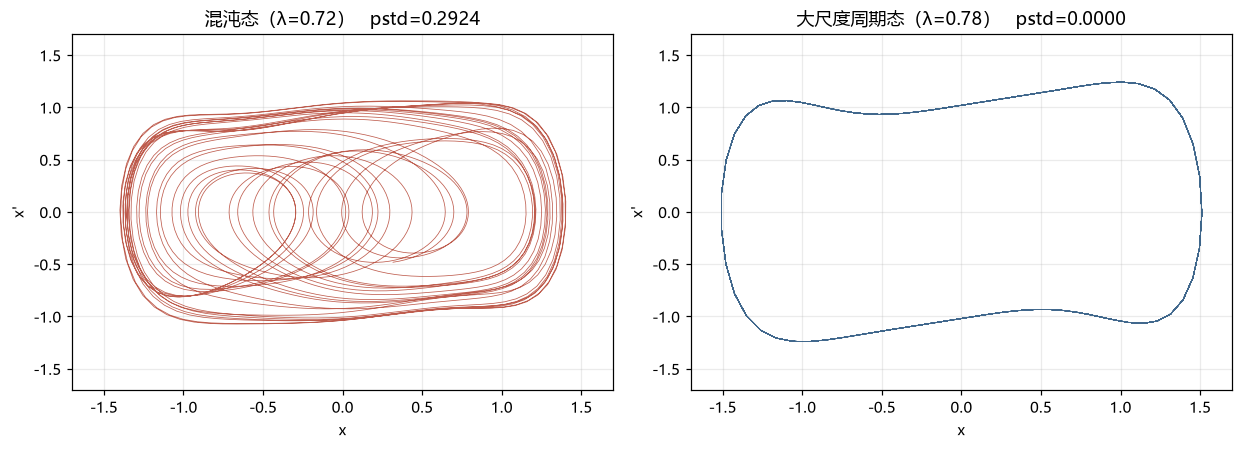

图已保存: ..\复现输出\s2-figs\s2-01-相图对比.png
混沌：轨迹填满一环；周期：轨迹收敛成一条闭合曲线。


In [3]:

d = load("fig1")
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.2))
for a, k, ttl, c in ((ax[0], "chaos", "混沌态（λ=0.72）", "#b3402f"),
                     (ax[1], "periodic", "大尺度周期态（λ=0.78）", "#1f4e79")):
    a.plot(k and d[k]["x"], d[k]["y"], lw=.5, color=c, alpha=.85)
    a.set_xlabel("x"); a.set_ylabel("x'")
    a.set_title(f"{ttl}   pstd={d['pstd'][0 if k=='chaos' else 1]:.4f}")
    a.set_xlim(-1.7, 1.7); a.set_ylim(-1.7, 1.7)
plt.tight_layout(); savefig("s2-01-相图对比.png")
print("混沌：轨迹填满一环；周期：轨迹收敛成一条闭合曲线。")
